In [1]:
import warnings
warnings.filterwarnings(action='ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
import seaborn as sns
import sklearn
from sklearn import datasets
sklearn.set_config(display='text')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, RobustScaler, MinMaxScaler, Normalizer
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score

In [2]:
from sklearn.tree import DecisionTreeClassifier

# 서울 지역(구)의 위도와 경도 정보를 학습해서 임의로 입력된 지역(동)을 분류하는 모델을 구현한다.

특정 동이 강동구인지 강서구인지 강남구인지 강북구인지 알아내는 모델을 구현한다.

district: 구, dong: 동, latitude: 위도, longitude: 경도, label: 강동, 강서, 강남, 강북으로 구분한 지역

In [3]:
# 구 데이터 => 학습 데이터
district_dict_list = [
    {'district': 'Gangseo-gu', 'latitude': 37.551000, 'longitude': 126.849500, 'label':'Gangseo'},
    {'district': 'Yangcheon-gu', 'latitude': 37.52424, 'longitude': 126.855396, 'label':'Gangseo'},
    {'district': 'Guro-gu', 'latitude': 37.4954, 'longitude': 126.8874, 'label':'Gangseo'},
    {'district': 'Geumcheon-gu', 'latitude': 37.4519, 'longitude': 126.9020, 'label':'Gangseo'},
    {'district': 'Mapo-gu', 'latitude': 37.560229, 'longitude': 126.908728, 'label':'Gangseo'},

    {'district': 'Gwanak-gu', 'latitude': 37.487517, 'longitude': 126.915065, 'label':'Gangnam'},
    {'district': 'Dongjak-gu', 'latitude': 37.5124, 'longitude': 126.9393, 'label':'Gangnam'},
    {'district': 'Seocho-gu', 'latitude': 37.4837, 'longitude': 127.0324, 'label':'Gangnam'},
    {'district': 'Gangnam-gu', 'latitude': 37.5172, 'longitude': 127.0473, 'label':'Gangnam'},
    {'district': 'Songpa-gu', 'latitude': 37.503510, 'longitude': 127.117898, 'label':'Gangnam'},

    {'district': 'Yongsan-gu', 'latitude': 37.532561, 'longitude': 127.008605, 'label':'Gangbuk'},
    {'district': 'Jongro-gu', 'latitude': 37.5730, 'longitude': 126.9794, 'label':'Gangbuk'},
    {'district': 'Seongbuk-gu', 'latitude': 37.603979, 'longitude': 127.056344, 'label':'Gangbuk'},
    {'district': 'Nowon-gu', 'latitude': 37.6542, 'longitude': 127.0568, 'label':'Gangbuk'},
    {'district': 'Dobong-gu', 'latitude': 37.6688, 'longitude': 127.0471, 'label':'Gangbuk'},

    {'district': 'Seongdong-gu', 'latitude': 37.557340, 'longitude': 127.041667, 'label':'Gangdong'},
    {'district': 'Dongdaemun-gu', 'latitude': 37.575759, 'longitude': 127.025288, 'label':'Gangdong'},
    {'district': 'Gwangjin-gu', 'latitude': 37.557562, 'longitude': 127.083467, 'label':'Gangdong'},
    {'district': 'Gangdong-gu', 'latitude': 37.554194, 'longitude': 127.151405, 'label':'Gangdong'},
    {'district': 'Jungrang-gu', 'latitude': 37.593684, 'longitude': 127.090384, 'label':'Gangdong'}
]

# 동 데이터 => 테스트 데이터
dong_dict_list = [
    {'dong': 'Gaebong-dong', 'latitude': 37.489853, 'longitude': 126.854547, 'label':'Gangseo'},
    {'dong': 'Gochuk-dong', 'latitude': 37.501394, 'longitude': 126.859245, 'label':'Gangseo'},
    {'dong': 'Hwagok-dong', 'latitude': 37.537759, 'longitude': 126.847951, 'label':'Gangseo'},
    {'dong': 'Banghwa-dong', 'latitude': 37.575817, 'longitude': 126.815719, 'label':'Gangseo'},
    {'dong': 'Sangam-dong', 'latitude': 37.577039, 'longitude': 126.891620, 'label':'Gangseo'},

    {'dong': 'Nonhyun-dong', 'latitude': 37.508838, 'longitude': 127.030720, 'label':'Gangnam'},
    {'dong': 'Daechi-dong', 'latitude': 37.501163, 'longitude': 127.057193, 'label':'Gangnam'},
    {'dong': 'Seocho-dong', 'latitude': 37.486401, 'longitude': 127.018281, 'label':'Gangnam'},
    {'dong': 'Bangbae-dong', 'latitude': 37.483279, 'longitude': 126.988194, 'label':'Gangnam'},
    {'dong': 'Dogok-dong', 'latitude': 37.492896, 'longitude': 127.043159, 'label':'Gangnam'},

    {'dong': 'Pyoungchang-dong', 'latitude': 37.612129, 'longitude': 126.975724, 'label':'Gangbuk'},
    {'dong': 'Sungbuk-dong', 'latitude': 37.597916, 'longitude': 126.998067, 'label':'Gangbuk'},
    {'dong': 'Ssangmoon-dong', 'latitude': 37.648094, 'longitude': 127.030421, 'label':'Gangbuk'},
    {'dong': 'Ui-dong', 'latitude': 37.648446, 'longitude': 127.011396, 'label':'Gangbuk'},
    {'dong': 'Samcheong-dong', 'latitude': 37.591109, 'longitude': 126.980488, 'label':'Gangbuk'},

    {'dong': 'Hwayang-dong', 'latitude': 37.544234, 'longitude': 127.071648, 'label':'Gangdong'},
    {'dong': 'Gui-dong', 'latitude': 37.543757, 'longitude': 127.086803, 'label':'Gangdong'},
    {'dong': 'Neung-dong', 'latitude': 37.553102, 'longitude': 127.080248, 'label':'Gangdong'},
    {'dong': 'Amsa-dong', 'latitude': 37.552370, 'longitude': 127.127124, 'label':'Gangdong'},
    {'dong': 'Chunho-dong', 'latitude': 37.547436, 'longitude': 127.137382, 'label':'Gangdong'}
]

## 구 데이터와 동 데이터를 데이터프레임으로 만든다.

In [4]:
train_df = pd.DataFrame(district_dict_list)
train_df.head()

,district,latitude,longitude,label
0,Gangseo-gu,37.551000,126.849500,Gangseo
1,Yangcheon-gu,37.524240,126.855396,Gangseo
2,Guro-gu,37.495400,126.887400,Gangseo
3,Geumcheon-gu,37.451900,126.902000,Gangseo
4,Mapo-gu,37.560229,126.908728,Gangseo


In [5]:
train_df.label.value_counts()

label
Gangseo     5
Gangnam     5
Gangbuk     5
Gangdong    5
Name: count, dtype: int64

In [6]:
test_df = pd.DataFrame(dong_dict_list)
test_df.head()

,dong,latitude,longitude,label
0,Gaebong-dong,37.489853,126.854547,Gangseo
1,Gochuk-dong,37.501394,126.859245,Gangseo
2,Hwagok-dong,37.537759,126.847951,Gangseo
3,Banghwa-dong,37.575817,126.815719,Gangseo
4,Sangam-dong,37.577039,126.891620,Gangseo


In [7]:
test_df.label.value_counts()

label
Gangseo     5
Gangnam     5
Gangbuk     5
Gangdong    5
Name: count, dtype: int64

## 시각화를 통해 데이터를 확인한다.

<Figure size 800x600 with 0 Axes>

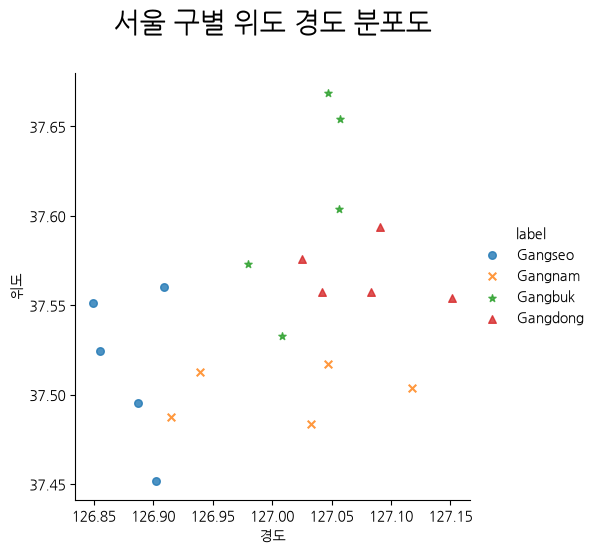

In [8]:
plt.figure(figsize=[8, 6])
sns.lmplot(data=train_df, x='longitude', y='latitude', fit_reg=False, hue='label', scatter_kws={'s': 30}, markers=['o', 'x', '*', '^'])
plt.title('서울 구별 위도 경도 분포도', pad=30, fontsize=20)
plt.xlabel('경도')
plt.ylabel('위도')
plt.show()

<Figure size 800x600 with 0 Axes>

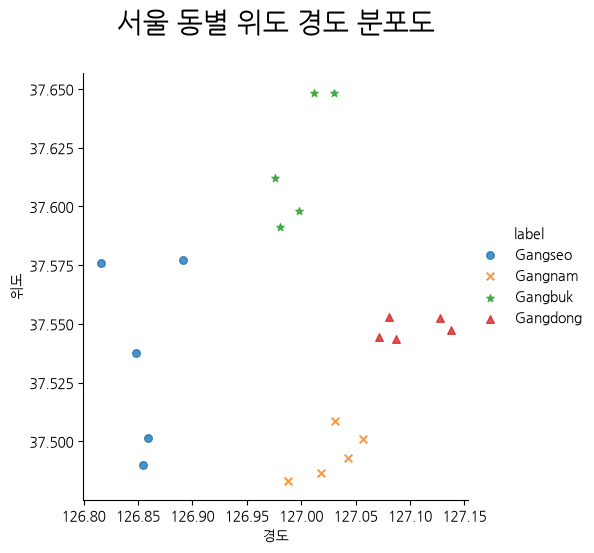

In [9]:
plt.figure(figsize=[8, 6])
sns.lmplot(data=test_df, x='longitude', y='latitude', fit_reg=False, hue='label', scatter_kws={'s': 30}, markers=['o', 'x', '*', '^'])
plt.title('서울 동별 위도 경도 분포도', pad=30, fontsize=20)
plt.xlabel('경도')
plt.ylabel('위도')
plt.show()

## 데이터 전처리

위의 시각화 결과를 통해 구 이름이나 동 이름이 학습이나 테스트에 별 영향을 미치지 않을것이라는 점을 알았으므로 학습 및 테스트 데이터에서 필요없는 피처를 제거한다.

In [10]:
# 학습 데이터에서 구 제거
train_df.drop(['district'], axis=1, inplace=True)
train_df.head()

,latitude,longitude,label
0,37.551000,126.849500,Gangseo
1,37.524240,126.855396,Gangseo
2,37.495400,126.887400,Gangseo
3,37.451900,126.902000,Gangseo
4,37.560229,126.908728,Gangseo


In [11]:
# 테스트 데이터에서 동 제거
test_df.drop(['dong'], axis=1, inplace=True)
test_df.head()

,latitude,longitude,label
0,37.489853,126.854547,Gangseo
1,37.501394,126.859245,Gangseo
2,37.537759,126.847951,Gangseo
3,37.575817,126.815719,Gangseo
4,37.577039,126.891620,Gangseo


학습 데이터와 테스트 데이터를 피처와 레이블로 나눈다.

In [12]:
x_train = train_df[['longitude', 'latitude']]
y_train = train_df[['label']]
x_test = test_df[['longitude', 'latitude']]
y_test = test_df[['label']]

기계처리에 적합하도록 label을 숫자로 변환한다.

Gangbuk: 0, Gangdong: 1, Gangnam: 2, Gangseo: 3

In [13]:
encode = LabelEncoder()
# encode.fit(y_train)
# y_train_encode = encode.transform(y_train)
y_train_encode = encode.fit_transform(y_train)
print(y_train_encode)
# LabelEncoder 클래스 객체의 classes_ 속성은 숫자로 변환된 워래 label을 얻어온다.
print(encode.classes_)

[3 3 3 3 3 2 2 2 2 2 0 0 0 0 0 1 1 1 1 1]
['Gangbuk' 'Gangdong' 'Gangnam' 'Gangseo']


## 의사결정 트리 모델을 만들고 학습시킨다. - 과적합 발생

In [14]:
model = DecisionTreeClassifier(random_state=35)
model.fit(x_train, y_train_encode)

DecisionTreeClassifier(random_state=35)

학습된 의사결정 트리 시각화

In [15]:
def decision_tree_surface(model, x, y):
    plt.figure(figsize=(8, 6))
    x_min = x.longitude.min() - 0.01
    x_max = x.longitude.max() + 0.01
    y_min = x.latitude.min() - 0.01
    y_max = x.latitude.max() + 0.01
    
    n_classes = len(encode.classes_)
    plot_color = 'rywb'
    plot_step = 0.001
    
    xx, yy = np.meshgrid(np.arange(x_min, x_max, plot_step), np.arange(y_min, y_max, plot_step))
    z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    z = z.reshape(xx.shape)
    
    plt.contourf(xx, yy, z, cmap=plt.cm.RdYlBu)
    plt.title('학습된 의사결정 트리 영역 그래프', pad=30, fontsize=20)
    plt.xlabel('경도')
    plt.ylabel('위도')
    
    for i, color in zip(range(n_classes), plot_color):
        idx = np.where(y == i)
        plt.scatter(x=x.loc[idx].longitude, y=x.loc[idx].latitude, c=color, edgecolors='k', s=80, label=encode.classes_[i])
    plt.legend(loc=1, bbox_to_anchor=(1.3, 1), fontsize=12)
    plt.show()

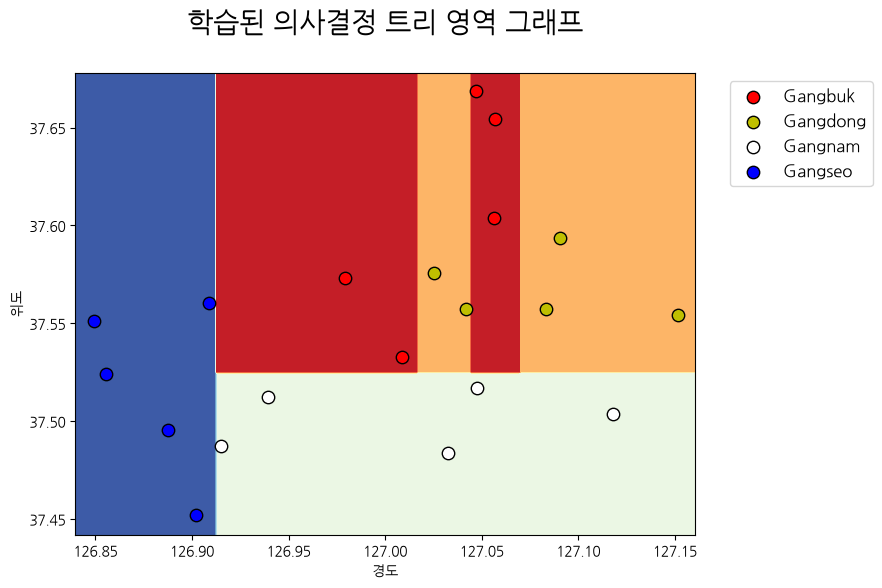

In [16]:
decision_tree_surface(model, x_train, y_train_encode)

의사결정 트리는 과적합되기 쉬운 모델이다. 아무런 파라미터 설정없이 학습 데이터를 학습한 의사결정 트리를 결정 표면(색으로 표시된 부분)을 시각화 해 보았다.  
강북 사이에 강동에 해당되는 데이터가 보이고 강동 사이에 강북에 해당되는 데이터가 보이는것으로 봐서 학습 데이터에만 너무 치우치게 학습되었다는 것을 알 수 있다. 즉, 과적합 되었다고 판단할 수 있다.  
사이킷런의 의사결정 트리는 과적합을 피할 수 있도록 파라미터를 제공하는데 제공되는 파라미터를 설정하지 않을 경우 과적합될 가능성이 상당히 높다.

## graphviz 라이브러리를 사용해서 의사결정 트리 시각화

graphviz 라이브러리는 의사결정 트리 모델이 학습한 결과를 트리 형태로 시각하고 PDF 파일로 출력도 가능하다.

graphviz 라이브러리를 사용하려면 아래의 과정을 먼저 실행해야 한다.  
`https://graphviz.org/download/`에서 graphviz 설치 파일을 다운로드 받아 설치한다.  
path 환경 변수에 `C:\Program Files\Graphviz\bin`를 추가해야 하는데 graphviz-8.1.0 버전 부터는 프로그램을 설치할 때 환경 변수에 추가하는 선택이 가능하다.  
`pip install graphviz`를 실행해서 graphviz 라이브러리를 설치하고 재부팅한다.

graphviz를 사용하기 위해 graphviz를 import

In [17]:
import graphviz

의사결정 트리 학습 결과를 graphviz 라이브러리의 데이터로 만들기 위해 export_graphviz를 import 한다.

In [18]:
from sklearn.tree import export_graphviz

export_graphviz() 함수로 의사결정 트리 모델, 피처 이름, 클래스 이름 등을 넘겨서 graphviz 객체를 만든다.

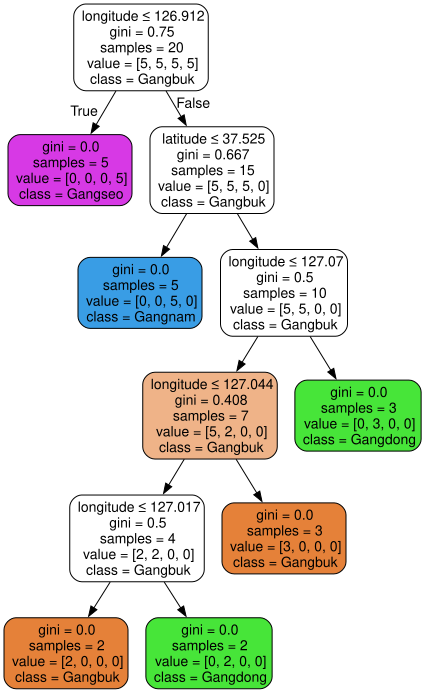

In [19]:
# graphviz 라이브러리로 시각화를 하기 위한 의사결정 트리의 데이터를 만든다.
dot = export_graphviz(
    decision_tree=model, # graphviz 라이브러리로 시각화 할 의사결정 트리 모델을 지정한다.
    feature_names=['longitude', 'latitude'], # 모델을 학습시킨 학습 데이터를 지정한다.
    class_names=['Gangbuk', 'Gangdong', 'Gangnam', 'Gangseo'], # 학습 데이터의 레이블을 지정한다.
    filled=True, # graphviz 실행 결과에 색을 채운다.
    rounded=True, # graphviz 실행 결과를 모서리가 둥근 사각형으로 만든다.
    special_characters=True # graphviz 실행 결과에 특수문자를 사용할 수 있게 한다.
)
# Source 클래스로 시각화를 하기 위한 의사결정 트리의 데이터를 넘겨서 graphviz 객체를 만든다.
graph = graphviz.Source(dot)
# render() 메소드로 graphviz 객체를 저장할 PDF 파일의 경로와 이름을 지정하면 PDF 파일로 저장된다.
graph.render('./output/seou1')
graph

## 의사결정 트리 모델을 만들고 학습시킨다. - 과적합 방지

In [20]:
model = DecisionTreeClassifier(
    random_state=35,
    max_depth=4, # 의사결정 트리의 최대 깊이, 과적합을 방지하기 위해서 max_depth는 지정하는 것이 좋다.
    min_samples_split=2, # 의사결정 트리가 자식 노드를 가지기 위한 최소한의 데이터 개수를 지정한다.
    min_samples_leaf=2, # 리프(터미널, 단노드) 노드의 최소 데이터 개수를 지정한다.
)
model.fit(x_train, y_train_encode)

DecisionTreeClassifier(max_depth=4, min_samples_leaf=2, random_state=35)

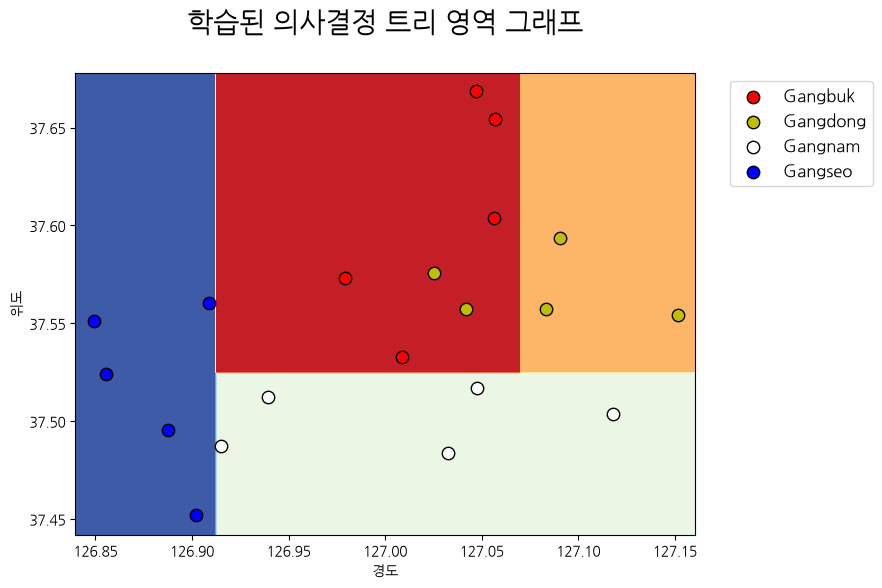

In [21]:
decision_tree_surface(model, x_train, y_train_encode)

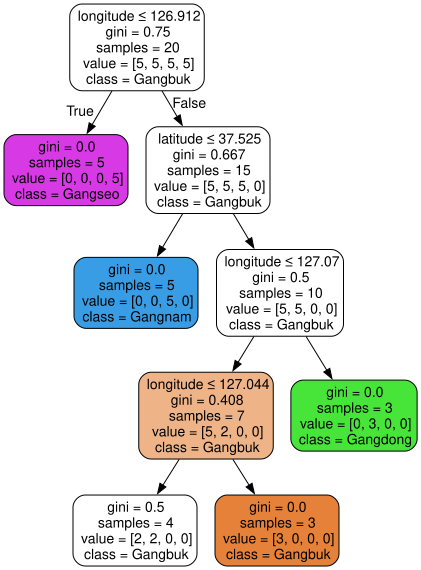

In [22]:
dot = export_graphviz(
    decision_tree=model, feature_names=['longitude', 'latitude'], class_names=['Gangbuk', 'Gangdong', 'Gangnam', 'Gangseo'], 
    filled=True, rounded=True, special_characters=True # graphviz 실행 결과에 특수문자를 사용할 수 있게 한다.
)
graph = graphviz.Source(dot)
graph.render('./output/seou2')
graph

## 모델 예측 후 테스트

In [30]:
predict = model.predict(x_test)
print(predict)
accuracy = accuracy_score(y_test, encode.classes_[predict])
print(f'정확도: {accuracy:.2%}')

[3 3 3 3 3 2 2 2 2 2 0 0 0 0 0 1 1 1 1 1]
정확도: 100.00%


ravel() 메소드는 2차원 이상의 배열을 무조건 1차원 배열로 만들어준다.

In [35]:
pd.DataFrame({'실제값': y_test.values.ravel(), '예측값': encode.classes_[predict]})

,실제값,예측값
0,Gangseo,Gangseo
1,Gangseo,Gangseo
2,Gangseo,Gangseo
3,Gangseo,Gangseo
4,Gangseo,Gangseo
5,Gangnam,Gangnam
6,Gangnam,Gangnam
7,Gangnam,Gangnam
8,Gangnam,Gangnam
9,Gangnam,Gangnam


# 완성된 모델 사용하기

In [39]:
dong_dict_list = [
    {'dong': 'Gaebong-dong', 'latitude': 37.489853, 'longitude': 126.854547, 'label':'Gangseo'},
    {'dong': 'Gochuk-dong', 'latitude': 37.501394, 'longitude': 126.859245, 'label':'Gangnam'},
    {'dong': 'Hwagok-dong', 'latitude': 37.537759, 'longitude': 126.847951, 'label':'Gangseo'},
    {'dong': 'Banghwa-dong', 'latitude': 37.575817, 'longitude': 126.815719, 'label':'Gangdong'},
    {'dong': 'Sangam-dong', 'latitude': 37.577039, 'longitude': 126.891620, 'label':'Gangseo'},
]
test_df = pd.DataFrame(dong_dict_list)
test_df.drop(['dong'], axis=1, inplace=True)
x_test = test_df[['longitude', 'latitude']]
y_test = test_df[['label']]

In [40]:
predict = model.predict(x_test)
print(predict)
accuracy = accuracy_score(y_test, encode.classes_[predict])
print(f'정확도: {accuracy:.2%}')

[3 3 3 3 3]
정확도: 60.00%


In [41]:
pd.DataFrame({'실제값': y_test.values.ravel(), '예측값': encode.classes_[predict]})

,실제값,예측값
0,Gangseo,Gangseo
1,Gangnam,Gangseo
2,Gangseo,Gangseo
3,Gangdong,Gangseo
4,Gangseo,Gangseo
